In [1]:
from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        p for p in [cwd, *cwd.parents]
        if (p / "data" / "processed").is_dir()
        and (p / "reports" / "tables").is_dir()
        and (p / "notebooks").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate ml-workstream-2. Expected data/processed, "
        "reports/tables and notebooks. Current directory: " + str(cwd)
    )

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
TABLES_DIR = REPORTS_DIR / "tables"
FIGURES_DIR = REPORTS_DIR / "figures"
DIAGNOSTICS_DIR = REPORTS_DIR / "diagnostics"
for folder in [TABLES_DIR, FIGURES_DIR, DIAGNOSTICS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Diagnostics output:", DIAGNOSTICS_DIR)

Project root: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2
Diagnostics output: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\diagnostics


In [2]:
FILES = {
    "predictions": TABLES_DIR / "loso_oof_predictions.csv",
    "fold_metrics": TABLES_DIR / "loso_fold_metrics.csv",
    "participant_metrics": TABLES_DIR / "loso_per_participant_metrics.csv",
    "comparison": TABLES_DIR / "loso_model_comparison.csv",
    "features": PROCESSED_DIR / "participant_phase_features.csv",
}
missing = [f"{name}: {path}" for name, path in FILES.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Required Notebook 04/03 outputs are missing:\n - " + "\n - ".join(missing)
    )

pred = pd.read_csv(FILES["predictions"])
folds = pd.read_csv(FILES["fold_metrics"])
participant_metrics = pd.read_csv(FILES["participant_metrics"])
comparison = pd.read_csv(FILES["comparison"])
features = pd.read_csv(FILES["features"])

print("Loaded local outputs:")
for name, frame in [
    ("OOF predictions", pred),
    ("Fold metrics", folds),
    ("Participant metrics", participant_metrics),
    ("Model comparison", comparison),
    ("Participant-phase features", features),
]:
    print(f"  {name}: {frame.shape[0]:,} rows × {frame.shape[1]:,} columns")

Loaded local outputs:
  OOF predictions: 1,884 rows × 8 columns
  Fold metrics: 966 rows × 12 columns
  Participant metrics: 966 rows × 9 columns
  Model comparison: 15 rows × 13 columns
  Participant-phase features: 132 rows × 48 columns


In [3]:
required_pred = {
    "experiment", "model", "participant_id", "phase",
    "y_true", "y_pred", "stress_probability", "fold"
}
missing_cols = required_pred - set(pred.columns)
if missing_cols:
    raise KeyError(f"OOF predictions missing columns: {sorted(missing_cols)}")

pred["participant_id"] = pred["participant_id"].astype("string").str.strip()
pred["phase"] = pred["phase"].astype("string").str.strip().str.lower()
pred["y_true"] = pd.to_numeric(pred["y_true"], errors="coerce")
pred["y_pred"] = pd.to_numeric(pred["y_pred"], errors="coerce")
pred["stress_probability"] = pd.to_numeric(pred["stress_probability"], errors="coerce")

if pred[["y_true", "y_pred", "stress_probability"]].isna().any().any():
    raise ValueError("Missing/non-numeric values found in prediction labels or probabilities.")
if not pred["y_true"].isin([0, 1]).all() or not pred["y_pred"].isin([0, 1]).all():
    raise ValueError("Expected binary labels 0=RELAX and 1=STRESS.")
if not pred["stress_probability"].between(0, 1).all():
    raise ValueError("stress_probability values must be within [0, 1].")

pred["expected_target"] = pred["phase"].map({"relax": 0, "stress": 1})
if pred["expected_target"].isna().any() or not (pred["expected_target"].astype(int) == pred["y_true"].astype(int)).all():
    raise ValueError("phase and y_true disagree. Revisit target construction in Notebook 04.")

key_cols = ["experiment", "model", "participant_id", "phase"]
duplicates = pred.duplicated(key_cols, keep=False)
if duplicates.any():
    display(pred.loc[duplicates, key_cols].sort_values(key_cols).head(20))
    raise ValueError("Duplicate OOF prediction keys found.")

integrity = pd.DataFrame([
    {"check": "prediction rows", "result": len(pred)},
    {"check": "experiments", "result": pred["experiment"].nunique()},
    {"check": "models", "result": pred["model"].nunique()},
    {"check": "participants represented", "result": pred["participant_id"].nunique()},
    {"check": "duplicate experiment/model/participant/phase keys", "result": int(duplicates.sum())},
    {"check": "probability minimum", "result": float(pred["stress_probability"].min())},
    {"check": "probability maximum", "result": float(pred["stress_probability"].max())},
])
display(integrity)
integrity.to_csv(DIAGNOSTICS_DIR / "prediction_integrity_checks.csv", index=False)
print("Prediction integrity checks passed.")

,check,result
0,prediction rows,1884.000000
1,experiments,5.000000
2,models,3.000000
3,participants represented,66.000000
4,duplicate experiment/model/participant/phase keys,0.000000
5,probability minimum,0.087313
6,probability maximum,0.934991


Prediction integrity checks passed.


,experiment,model,balanced_accuracy,macro_f1,accuracy,relax_recall_specificity,stress_recall_sensitivity,n_observations,n_participants
0,ECG + EDA — paired cohort,Gradient Boosting,0.561979,0.560399,0.564516,0.640625,0.483333,124,64
3,ECG — all eligible rows,Gradient Boosting,0.598485,0.596610,0.598485,0.666667,0.530303,132,66
6,ECG — paired cohort,Gradient Boosting,0.601042,0.597269,0.604839,0.718750,0.483333,124,64
9,EDA — all available rows,Random Forest,0.693229,0.693229,0.693548,0.703125,0.683333,124,64
12,EDA — paired cohort,Random Forest,0.693229,0.693229,0.693548,0.703125,0.683333,124,64


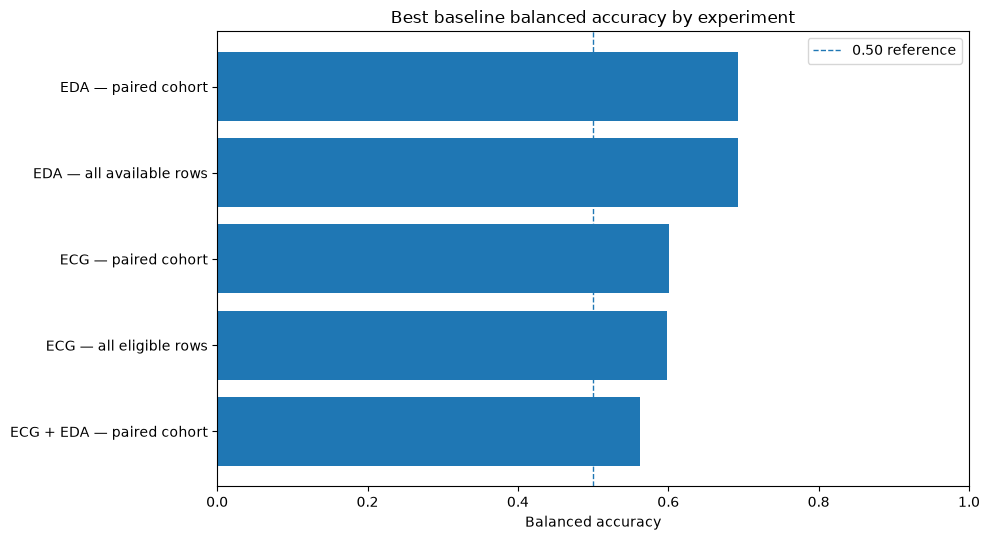

This is a descriptive ranking only; best score does not establish final model suitability.


In [4]:
needed_comparison = {
    "experiment", "model", "balanced_accuracy", "macro_f1", "accuracy",
    "relax_recall_specificity", "stress_recall_sensitivity"
}
missing_cols = needed_comparison - set(comparison.columns)
if missing_cols:
    raise KeyError(f"Model comparison table missing columns: {sorted(missing_cols)}")

comparison = comparison.sort_values(
    ["experiment", "balanced_accuracy", "macro_f1"],
    ascending=[True, False, False]
).reset_index(drop=True)

best_by_experiment = comparison.groupby("experiment", as_index=False, sort=False).head(1).copy()
display(best_by_experiment[[
    "experiment", "model", "balanced_accuracy", "macro_f1", "accuracy",
    "relax_recall_specificity", "stress_recall_sensitivity", "n_observations", "n_participants"
]])
best_by_experiment.to_csv(DIAGNOSTICS_DIR / "best_model_by_experiment.csv", index=False)

# Chart the best baseline result for each experiment.
plot_df = best_by_experiment.sort_values("balanced_accuracy", ascending=True)
plt.figure(figsize=(10, 5.5))
plt.barh(plot_df["experiment"], plot_df["balanced_accuracy"])
plt.axvline(0.5, linestyle="--", linewidth=1, label="0.50 reference")
plt.xlim(0, 1)
plt.xlabel("Balanced accuracy")
plt.title("Best baseline balanced accuracy by experiment")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "diagnostic_best_model_by_experiment.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()
print("This is a descriptive ranking only; best score does not establish final model suitability.")

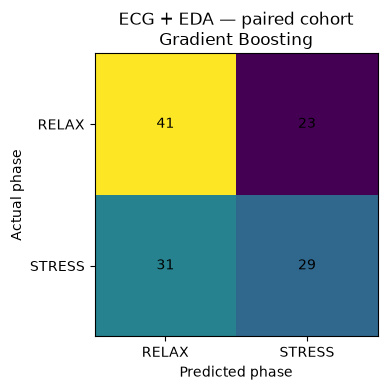

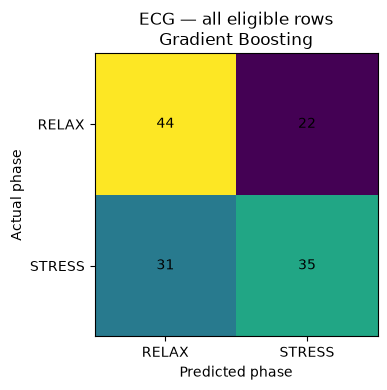

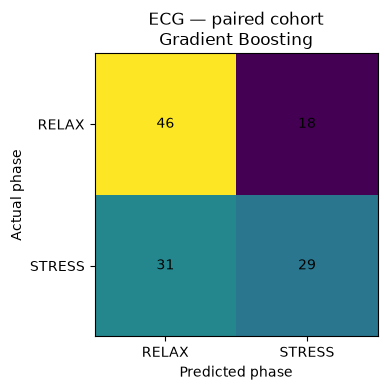

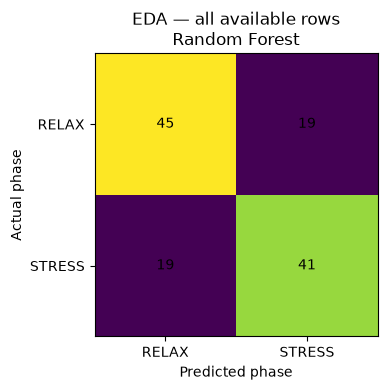

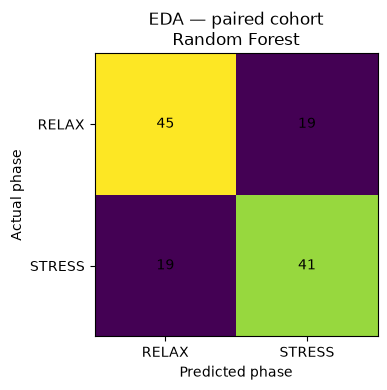

,experiment,model,true_relax_pred_relax,true_relax_pred_stress,true_stress_pred_relax,true_stress_pred_stress
0,ECG + EDA — paired cohort,Gradient Boosting,41,23,31,29
1,ECG — all eligible rows,Gradient Boosting,44,22,31,35
2,ECG — paired cohort,Gradient Boosting,46,18,31,29
3,EDA — all available rows,Random Forest,45,19,19,41
4,EDA — paired cohort,Random Forest,45,19,19,41


In [6]:
def confusion_counts(frame):
    y_true = frame["y_true"].astype(int).to_numpy()
    y_pred = frame["y_pred"].astype(int).to_numpy()
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return np.array([[tn, fp], [fn, tp]], dtype=int)

cm_rows = []
for _, choice in best_by_experiment.iterrows():
    subset = pred.loc[
        (pred["experiment"] == choice["experiment"])
        & (pred["model"] == choice["model"])
    ].copy()
    cm = confusion_counts(subset)
    cm_rows.append({
        "experiment": choice["experiment"], "model": choice["model"],
        "true_relax_pred_relax": cm[0, 0],
        "true_relax_pred_stress": cm[0, 1],
        "true_stress_pred_relax": cm[1, 0],
        "true_stress_pred_stress": cm[1, 1],
    })
    fig, ax = plt.subplots(figsize=(4.8, 4.0))
    ax.imshow(cm, interpolation="nearest")
    ax.set_title(f"{choice['experiment']}\n{choice['model']}")
    ax.set_xlabel("Predicted phase")
    ax.set_ylabel("Actual phase")
    ax.set_xticks([0, 1], ["RELAX", "STRESS"])
    ax.set_yticks([0, 1], ["RELAX", "STRESS"])
    for (r, c), value in np.ndenumerate(cm):
        ax.text(c, r, str(value), ha="center", va="center")
    fig.tight_layout()
    safe_name = "".join(ch.lower() if ch.isalnum() else "_" for ch in str(choice["experiment"])).strip("_")
    fig.savefig(FIGURES_DIR / f"confusion_{safe_name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

cm_table = pd.DataFrame(cm_rows)
display(cm_table)
cm_table.to_csv(DIAGNOSTICS_DIR / "best_model_confusion_counts.csv", index=False)

,experiment,model,participants,median_participant_accuracy,mean_participant_accuracy,participants_below_50pct_accuracy,participants_at_or_above_80pct_accuracy
0,ECG — all eligible rows,Gradient Boosting,66,0.50,0.598485,6,19
1,EDA — all available rows,Random Forest,64,0.75,0.695312,7,32
2,ECG — paired cohort,Gradient Boosting,64,0.50,0.609375,7,21
3,EDA — paired cohort,Random Forest,64,0.75,0.695312,7,32
4,ECG + EDA — paired cohort,Gradient Boosting,64,0.50,0.562500,13,21


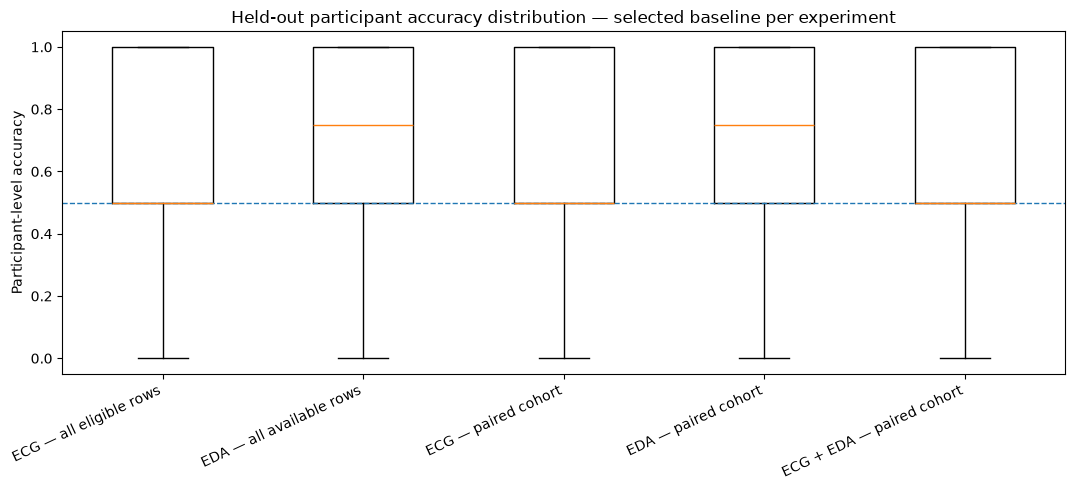

In [7]:
# Focus on the selected model per experiment, using the already saved held-out predictions.
selected_keys = best_by_experiment[["experiment", "model"]]
selected_participant_rows = participant_metrics.merge(
    selected_keys, on=["experiment", "model"], how="inner", validate="many_to_one"
)

summary_rows = []
for experiment, grp in selected_participant_rows.groupby("experiment", sort=False):
    vals = pd.to_numeric(grp["accuracy"], errors="coerce").dropna()
    summary_rows.append({
        "experiment": experiment,
        "model": grp["model"].iloc[0],
        "participants": int(grp["participant_id"].nunique()),
        "median_participant_accuracy": float(vals.median()) if len(vals) else np.nan,
        "mean_participant_accuracy": float(vals.mean()) if len(vals) else np.nan,
        "participants_below_50pct_accuracy": int((vals < 0.5).sum()),
        "participants_at_or_above_80pct_accuracy": int((vals >= 0.8).sum()),
    })
participant_summary = pd.DataFrame(summary_rows)
display(participant_summary)
participant_summary.to_csv(DIAGNOSTICS_DIR / "participant_performance_summary.csv", index=False)
selected_participant_rows.to_csv(DIAGNOSTICS_DIR / "selected_models_participant_metrics.csv", index=False)

# Plot participant accuracy distributions for all selected experiments.
plot_groups, plot_labels = [], []
for experiment, grp in selected_participant_rows.groupby("experiment", sort=False):
    vals = pd.to_numeric(grp["accuracy"], errors="coerce").dropna().to_numpy()
    if len(vals):
        plot_groups.append(vals)
        plot_labels.append(experiment)
if plot_groups:
    plt.figure(figsize=(11, 5))
    plt.boxplot(plot_groups, tick_labels=plot_labels)
    plt.axhline(0.5, linestyle="--", linewidth=1)
    plt.ylabel("Participant-level accuracy")
    plt.title("Held-out participant accuracy distribution — selected baseline per experiment")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "participant_accuracy_distributions.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

,feature,paired_participants,relax_median,stress_median,median_stress_minus_relax,participants_with_increase_pct,participants_with_decrease_pct,participants_with_no_change_pct
2,eda_scl_std_us,60,0.776688,1.073830,0.186109,71.666667,28.333333,0.0
3,eda_scl_mad_us,60,0.362500,0.460000,0.105000,68.333333,31.666667,0.0
4,eda_scl_iqr_us,60,0.860000,1.005000,0.360000,63.333333,36.666667,0.0
6,eda_scl_max_us,60,43.185000,42.220000,0.200000,55.000000,45.000000,0.0
0,eda_scl_mean_us,60,41.227883,39.226781,-0.016866,50.000000,50.000000,0.0
1,eda_scl_median_us,60,41.375000,39.327500,0.010000,50.000000,50.000000,0.0
5,eda_scl_min_us,60,36.250000,35.120000,-0.520000,40.000000,60.000000,0.0
7,eda_scl_slope_us_per_sec,60,-0.001986,-0.002181,-0.005402,38.333333,61.666667,0.0


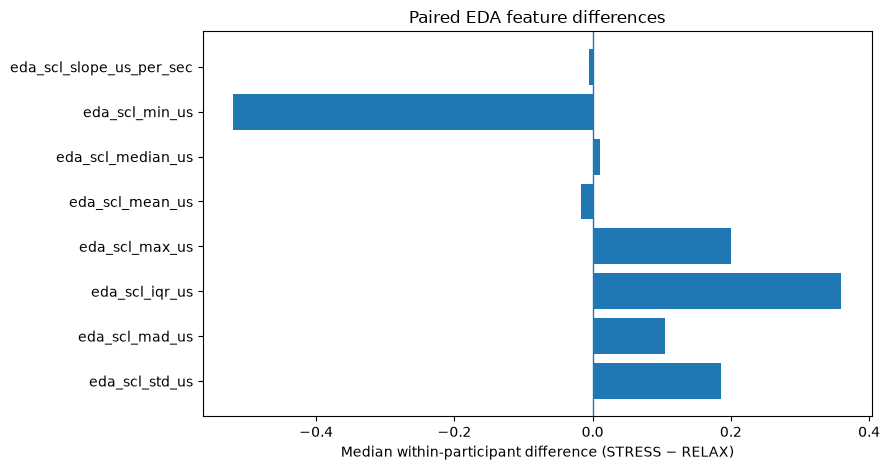

In [8]:
# This is descriptive paired analysis, not a model-importance estimate.
# Compare each participant's STRESS value with their own RELAX value.
required_feature_cols = {"participant_id", "phase"}
if not required_feature_cols.issubset(features.columns):
    raise KeyError("Feature table must contain participant_id and phase.")

features["participant_id"] = features["participant_id"].astype("string").str.strip()
features["phase"] = features["phase"].astype("string").str.strip().str.lower()

eda_candidates = [
    c for c in [
        "eda_scl_mean_us", "eda_scl_median_us", "eda_scl_std_us",
        "eda_scl_mad_us", "eda_scl_iqr_us", "eda_scl_min_us",
        "eda_scl_max_us", "eda_scl_slope_us_per_sec"
    ] if c in features.columns
]
if not eda_candidates:
    print("No recognised EDA feature columns found; skipping paired EDA feature analysis.")
    paired_eda_summary = pd.DataFrame()
else:
    eda_wide = features.loc[
        features["phase"].isin(["relax", "stress"]),
        ["participant_id", "phase"] + eda_candidates
    ].copy()
    for col in eda_candidates:
        eda_wide[col] = pd.to_numeric(eda_wide[col], errors="coerce")
    # Duplicate participant-phase records would make pivot ambiguous, so fail clearly.
    if eda_wide.duplicated(["participant_id", "phase"]).any():
        raise ValueError("Duplicate participant-phase rows in feature table; cannot form paired EDA differences.")
    relax = eda_wide.loc[eda_wide["phase"] == "relax"].set_index("participant_id")
    stress = eda_wide.loc[eda_wide["phase"] == "stress"].set_index("participant_id")
    common = relax.index.intersection(stress.index)
    pair_rows = []
    for col in eda_candidates:
        paired = pd.DataFrame({"relax": relax.loc[common, col], "stress": stress.loc[common, col]}).dropna()
        diff = paired["stress"] - paired["relax"]
        pair_rows.append({
            "feature": col,
            "paired_participants": int(len(paired)),
            "relax_median": float(paired["relax"].median()) if len(paired) else np.nan,
            "stress_median": float(paired["stress"].median()) if len(paired) else np.nan,
            "median_stress_minus_relax": float(diff.median()) if len(diff) else np.nan,
            "participants_with_increase_pct": float((diff > 0).mean() * 100) if len(diff) else np.nan,
            "participants_with_decrease_pct": float((diff < 0).mean() * 100) if len(diff) else np.nan,
            "participants_with_no_change_pct": float((diff == 0).mean() * 100) if len(diff) else np.nan,
        })
    paired_eda_summary = pd.DataFrame(pair_rows).sort_values(
        "participants_with_increase_pct", ascending=False, na_position="last"
    )
    display(paired_eda_summary)
    paired_eda_summary.to_csv(DIAGNOSTICS_DIR / "paired_eda_phase_differences.csv", index=False)

    if not paired_eda_summary.empty:
        p = paired_eda_summary.dropna(subset=["median_stress_minus_relax"])
        if not p.empty:
            plt.figure(figsize=(9, 4.8))
            plt.barh(p["feature"], p["median_stress_minus_relax"])
            plt.axvline(0, linewidth=1)
            plt.xlabel("Median within-participant difference (STRESS − RELAX)")
            plt.title("Paired EDA feature differences")
            plt.tight_layout()
            plt.savefig(FIGURES_DIR / "paired_eda_phase_differences.png", dpi=160, bbox_inches="tight")
            plt.show()
            plt.close()

Diagnostic probability distribution: EDA — all available rows / Random Forest
RELAX: n=64, mean predicted stress probability=0.392, median=0.396
STRESS: n=60, mean predicted stress probability=0.571, median=0.582


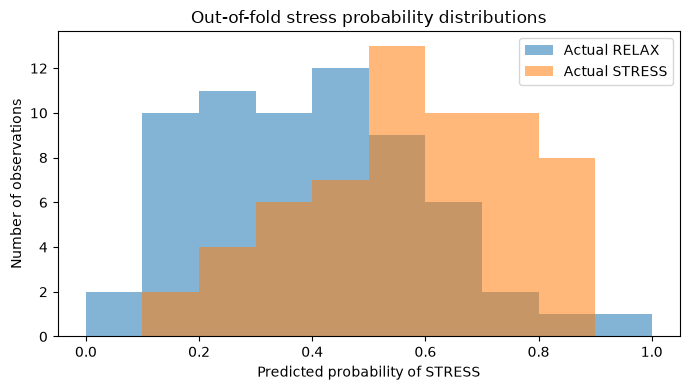

No alternative threshold was selected. Any future threshold must be developed within training data, not chosen using these same held-out predictions.


In [9]:
# Choose the best EDA experiment result from the comparison table, if present.
eda_choices = best_by_experiment.loc[best_by_experiment["experiment"].str.startswith("EDA", na=False)]
if eda_choices.empty:
    print("No EDA experiment found in the comparison table.")
else:
    chosen = eda_choices.sort_values("balanced_accuracy", ascending=False).iloc[0]
    probability_rows = pred.loc[
        (pred["experiment"] == chosen["experiment"])
        & (pred["model"] == chosen["model"])
    ].copy()
    print("Diagnostic probability distribution:", chosen["experiment"], "/", chosen["model"])
    for target, label in [(0, "RELAX"), (1, "STRESS")]:
        vals = probability_rows.loc[probability_rows["y_true"] == target, "stress_probability"].to_numpy()
        if len(vals):
            print(f"{label}: n={len(vals)}, mean predicted stress probability={vals.mean():.3f}, median={np.median(vals):.3f}")

    plt.figure(figsize=(7, 4))
    for target, label in [(0, "Actual RELAX"), (1, "Actual STRESS")]:
        vals = probability_rows.loc[probability_rows["y_true"] == target, "stress_probability"].to_numpy()
        if len(vals):
            plt.hist(vals, bins=np.linspace(0, 1, 11), alpha=0.55, label=label)
    plt.xlabel("Predicted probability of STRESS")
    plt.ylabel("Number of observations")
    plt.title("Out-of-fold stress probability distributions")
    plt.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "eda_best_model_stress_probability_distribution.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()

    print("No alternative threshold was selected. Any future threshold must be developed within training data, not chosen using these same held-out predictions.")

In [10]:
report = [
    "# Baseline Diagnostics & Error Analysis Report",
    "",
    f"- Project: `{PROJECT_ROOT}`",
    f"- OOF prediction rows: {len(pred):,}",
    f"- Experiments: {pred['experiment'].nunique()}",
    f"- Models: {pred['model'].nunique()}",
    f"- Participants represented: {pred['participant_id'].nunique()}",
    "",
    "## Best baseline per experiment",
]
for _, row in best_by_experiment.iterrows():
    report.append(
        f"- **{row['experiment']} / {row['model']}**: balanced accuracy "
        f"{row['balanced_accuracy']:.3f}, macro-F1 {row['macro_f1']:.3f}, "
        f"RELAX recall {row['relax_recall_specificity']:.3f}, "
        f"STRESS recall {row['stress_recall_sensitivity']:.3f}."
    )
report += ["", "## Participant-level distribution"]
for _, row in participant_summary.iterrows():
    report.append(
        f"- **{row['experiment']} / {row['model']}**: {int(row['participants'])} participants; "
        f"median participant accuracy {row['median_participant_accuracy']:.3f}; "
        f"{int(row['participants_below_50pct_accuracy'])} participants below 50% accuracy."
    )
report += ["", "## Paired EDA observations"]
if 'paired_eda_summary' in globals() and not paired_eda_summary.empty:
    for _, row in paired_eda_summary.iterrows():
        report.append(
            f"- `{row['feature']}`: {int(row['paired_participants'])} paired participants; "
            f"median STRESS−RELAX difference {row['median_stress_minus_relax']:.6g}; "
            f"increase in {row['participants_with_increase_pct']:.1f}% of paired participants."
        )
else:
    report.append("- Paired EDA feature summary was unavailable.")
report += [
    "",
    "## Interpretation and limitations",
    "- These results are out-of-fold predictions from the saved participant-independent LOSO baseline run.",
    "- Selecting the top score per experiment is descriptive; it is not final model approval.",
    "- Participant-level results are variable and the cohort is small. Review the complete CSV tables and plots before making claims.",
    "- Paired EDA feature differences are descriptive within-participant comparisons, not feature importance and not causal evidence.",
    "- No threshold was tuned on held-out predictions.",
    "- The task is controlled experimental RELAX/STRESS phase classification; it does not diagnose chronic stress or establish astronaut/spaceflight generalization.",
    "",
    "## Generated artifacts",
    "- `reports/diagnostics/prediction_integrity_checks.csv`",
    "- `reports/diagnostics/best_model_by_experiment.csv`",
    "- `reports/diagnostics/best_model_confusion_counts.csv`",
    "- `reports/diagnostics/participant_performance_summary.csv`",
    "- `reports/diagnostics/selected_models_participant_metrics.csv`",
    "- `reports/diagnostics/paired_eda_phase_differences.csv` (when EDA features are present)",
    "- Figures saved under `reports/figures/` with `diagnostic_`, `confusion_`, `participant_`, or `paired_eda_` prefixes.",
]
report_path = DIAGNOSTICS_DIR / "baseline_diagnostics_report.md"
report_path.write_text("\n".join(report), encoding="utf-8")
print("Saved:", report_path)
print("Diagnostics complete. All analysis was performed locally; no files need to be uploaded.")

Saved: D:\Projects\TakeOFF\astronaut_health_spec_v0_2\astronaut_health_spec\ml-workstream-2\reports\diagnostics\baseline_diagnostics_report.md
Diagnostics complete. All analysis was performed locally; no files need to be uploaded.
